# Swin Tiny for Deployment: Patient-Level Training, Threshold Selection, Grad-CAM and Export

This notebook takes the best model from the comparative study (Swin Tiny, `swin_tiny_patch4_window7_224`) and prepares it for deployment in a FastAPI + Docker app on Hugging Face Spaces.

Compared with the study notebook, it changes four things:

1. **Patient-level evaluation.** Images are grouped by the patient ID in the BreakHis filename, so no patient appears in more than one of train, validation and test. Performance is estimated with **5-fold `StratifiedGroupKFold`** and reported as mean ± std.
2. **Leakage-prone baseline.** The original image-level split (seed 42) is re-run with the same procedure and reported separately, labelled *leakage-prone baseline*, so the two numbers can be compared.
3. **Explicit decision threshold.** The threshold is chosen on validation data as the highest value that keeps **malignant recall ≥ 0.95**. Test metrics are reported at that threshold and at 0.5 for reference.
4. **Deployment export.** The weights (safetensors), the exact preprocessing, the threshold, the metrics, the dataset statistics and the library versions are saved to `deployment_artifacts/`. The export is then reloaded and checked, including on CPU, which is what the app will run on.

**Runtime.** About 30–45 minutes on a Colab T4: 5 CV folds, 1 baseline run and 1 final run, each up to 10 epochs.

**Before running:** select *Runtime → Change runtime type → GPU*, and check `BASE_DIR` in the configuration cell.

## 1. Environment

`timm` and `torchvision` are already installed on Colab. `grad-cam` provides Grad-CAM, and `safetensors` stores the weights in a format that, unlike pickle, cannot execute code when it is loaded. All library versions are recorded so the deployment container can pin the same ones.

In [1]:
%pip install -q timm grad-cam safetensors

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os
import re
import json
import time
import math
import random
import shutil
import hashlib
import zipfile
import platform
import warnings
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version as pkg_version, PackageNotFoundError
from typing import Dict, List, Optional, Tuple, Callable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve, confusion_matrix,
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms as T
import timm
from timm.data import IMAGENET_DEFAULT_MEAN, IMAGENET_DEFAULT_STD
from safetensors.torch import save_file, load_file

import cv2
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

warnings.filterwarnings('ignore', category=UserWarning)
sns.set_theme(style='whitegrid')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type != 'cuda':
    print('WARNING: no GPU detected. Training will be very slow. '
          'Use Runtime -> Change runtime type -> GPU.')


def dist_version(*names: str) -> Optional[str]:
    """Return the installed version of the first distribution found, else None."""
    for name in names:
        try:
            return pkg_version(name)
        except PackageNotFoundError:
            continue
    return None


VERSIONS = {
    'python': platform.python_version(),
    'torch': torch.__version__,
    'torchvision': torchvision.__version__,
    'timm': timm.__version__,
    'grad-cam': dist_version('grad-cam'),
    'safetensors': dist_version('safetensors'),
    'numpy': np.__version__,
    'pillow': dist_version('pillow', 'Pillow'),
    'opencv': cv2.__version__,
    'opencv_distribution': next(
        (f'{n}=={dist_version(n)}' for n in
         ('opencv-python-headless', 'opencv-python', 'opencv-contrib-python')
         if dist_version(n)), None),
    'scikit-learn': dist_version('scikit-learn'),
    'cuda': torch.version.cuda,
    'gpu': torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else None,
}
print('Device:', DEVICE)
print(json.dumps(VERSIONS, indent=2))

Device: cuda
{
  "python": "3.13.16",
  "torch": "2.14.1+cu130",
  "torchvision": "0.29.1+cu130",
  "timm": "1.0.31",
  "grad-cam": "1.5.7",
  "safetensors": "0.8.0",
  "numpy": "2.4.6",
  "pillow": "11.3.0",
  "opencv": "4.14.0",
  "opencv_distribution": "opencv-python-headless==5.0.0.93",
  "scikit-learn": "1.6.1",
  "cuda": "13.0",
  "gpu": "Tesla T4"
}


## 2. Configuration

The training hyperparameters are the same as in the comparative study, so the only changes are the split protocol and the threshold. `N_FOLDS = 5` gives about 16 test patients per fold. BreakHis 100X has 82 patients (24 benign, 58 malignant).

In [3]:
# ---- Data location (same as the study notebook) ----
BASE_DIR = '/content/drive/MyDrive/DATASET MASTERS THESIS/Breast Cancer'
ZIP_FILENAME = 'Breast_hist.zip'
MAGNIFICATIONS = ['40X', '100X', '200X', '400X']
CLASSES = ['benign', 'malignant']
LABEL_MAP = {'benign': 0, 'malignant': 1}       # index 1 = positive class
MAGNIFICATION = '100X'

# Copy the 100X images from Drive to the Colab disk once; reading from Drive every epoch is slow.
COPY_TO_LOCAL_DISK = True
LOCAL_DATA_DIR = Path('/content/breakhis_100x')

# ---- Model and training (unchanged from the study) ----
TIMM_MODEL_NAME = 'swin_tiny_patch4_window7_224'
IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_EPOCHS = 10
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
EARLY_STOPPING_PATIENCE = 3
EARLY_STOPPING_MIN_DELTA = 1e-4
NUM_WORKERS = 2
SEED = 42

# ---- Evaluation protocol ----
N_FOLDS = 5                      # patient-level outer folds (test)
INNER_VAL_FRACTION = 0.15        # fraction of a training portion's patients held out for validation
MIN_VAL_PATIENTS_PER_CLASS = 2   # reject a validation split with fewer patients than this in either class
TARGET_MALIGNANT_RECALL = 0.95   # threshold-selection constraint, applied on validation
REFERENCE_THRESHOLD = 0.5
RUN_LEAKAGE_BASELINE = True      # re-run the original image-level split for comparison

# ---- Outputs ----
ARTIFACT_DIR = Path(BASE_DIR) / 'deployment_artifacts'
WEIGHTS_FILENAME = 'swin_tiny_breakhis.safetensors'
BREAKHIS_URL = 'https://web.inf.ufpr.br/vri/databases/breast-cancer-histopathological-database-breakhis/'


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(SEED)
torch.backends.cudnn.benchmark = True

## 3. Locating the dataset

This reuses the study notebook's code: mount Drive, find the folder that contains `40X/100X/200X/400X` with `benign`/`malignant` subfolders, and extract `Breast_hist.zip` if the data is not already unpacked.

In [4]:
def mount_google_drive() -> bool:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        return True
    except ImportError:
        print('Not running on Colab - skipping Drive mount.')
        return False


def find_data_root(search_dir: Path, magnifications: List[str],
                   classes: Optional[List[str]] = None) -> Optional[Path]:
    """Find a folder that directly contains all magnification folders (each with the class folders)."""
    search_dir = Path(search_dir)
    if not search_dir.is_dir():
        return None
    for root, dirs, _ in os.walk(search_dir):
        if not all(m in dirs for m in magnifications):
            continue
        root_path = Path(root)
        if classes is None:
            return root_path
        ok = True
        for m in magnifications:
            subs = {d.lower() for d in os.listdir(root_path / m) if (root_path / m / d).is_dir()}
            if not all(c.lower() in subs for c in classes):
                ok = False
                break
        if ok:
            return root_path
    return None


def ensure_dataset_extracted(base_dir: str, zip_filename: str, magnifications: List[str],
                             classes: List[str]) -> Path:
    base_dir = Path(base_dir)
    root = find_data_root(base_dir, magnifications, classes)
    if root is not None:
        print(f'Found existing data root: {root}')
        return root
    zip_path, extract_dir = base_dir / zip_filename, base_dir / 'data'
    if zip_path.exists():
        extract_dir.mkdir(parents=True, exist_ok=True)
        print(f'Extracting {zip_path} ...')
        with zipfile.ZipFile(zip_path) as zf:
            zf.extractall(extract_dir)
        root = find_data_root(extract_dir, magnifications, classes)
        if root is not None:
            return root
    raise FileNotFoundError(f'No BreakHis folder with {magnifications} / {classes} under {base_dir}, '
                            f'and no usable {zip_filename}.')


mount_google_drive()
DATA_ROOT = ensure_dataset_extracted(BASE_DIR, ZIP_FILENAME, MAGNIFICATIONS, CLASSES)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
print('Data root:', DATA_ROOT)
print('Artifacts will be written to:', ARTIFACT_DIR)

Mounted at /content/drive
Found existing data root: /content/drive/MyDrive/DATASET MASTERS THESIS/Breast Cancer/BreakHis - Breast Cancer Histopathological Database/dataset_cancer_v1/dataset_cancer_v1/classificacao_binaria
Data root: /content/drive/MyDrive/DATASET MASTERS THESIS/Breast Cancer/BreakHis - Breast Cancer Histopathological Database/dataset_cancer_v1/dataset_cancer_v1/classificacao_binaria
Artifacts will be written to: /content/drive/MyDrive/DATASET MASTERS THESIS/Breast Cancer/deployment_artifacts


## 4. Indexing 100X images and parsing patient IDs

BreakHis filenames encode the patient, for example `SOB_B_A-14-22549AB-100-001.png`:

| Part | Meaning |
|---|---|
| `B` / `M` | benign / malignant |
| `A` | tumour subtype (A, F, PT, TA benign; DC, LC, MC, PC malignant) |
| `14-22549AB` | **patient ID** (year + slide ID), used as the group |
| `100` | magnification |
| `001` | image number |

The checks below stop the notebook if any filename cannot be parsed, if the class letter in a filename disagrees with its folder, or if a patient appears in both classes. Each of these would make a patient-level split invalid. A patient spanning more than one *subtype* within the same class is reported but allowed, because the task is binary.

In [5]:
IMAGE_EXTENSIONS = ('png', 'jpg', 'jpeg', 'tif', 'tiff', 'bmp')

BREAKHIS_PATTERN = re.compile(
    r'^SOB_(?P<cls>[BM])_(?P<subtype>[A-Z]+)-(?P<year>\d+)-(?P<slide>[0-9A-Za-z]+)'
    r'-(?P<mag>\d+)-(?P<seq>\d+)\.(?P<ext>[A-Za-z]+)$'
)
SUBTYPE_NAMES = {
    'A': 'adenosis', 'F': 'fibroadenoma', 'PT': 'phyllodes tumour', 'TA': 'tubular adenoma',
    'DC': 'ductal carcinoma', 'LC': 'lobular carcinoma', 'MC': 'mucinous carcinoma',
    'PC': 'papillary carcinoma',
}


def resolve_class_dir(mag_dir: Path, class_name: str) -> Optional[Path]:
    for d in mag_dir.iterdir():
        if d.is_dir() and d.name.lower() == class_name.lower():
            return d
    return None


def find_images(folder: Path) -> List[Path]:
    found = set()
    for ext in IMAGE_EXTENSIONS:
        found.update(folder.rglob(f'*.{ext}'))
        found.update(folder.rglob(f'*.{ext.upper()}'))
    return sorted(found)


def parse_breakhis_filename(name: str) -> Optional[Dict[str, str]]:
    m = BREAKHIS_PATTERN.match(name)
    if m is None:
        return None
    g = m.groupdict()
    return {
        'file_class': 'benign' if g['cls'] == 'B' else 'malignant',
        'subtype': g['subtype'],
        'patient_id': f"{g['year']}-{g['slide']}",
        'file_magnification': f"{g['mag']}X",
    }


records = []
for cls in CLASSES:
    cls_dir = resolve_class_dir(DATA_ROOT / MAGNIFICATION, cls)
    if cls_dir is None:
        raise FileNotFoundError(f'No "{cls}" folder under {DATA_ROOT / MAGNIFICATION}')
    for p in find_images(cls_dir):
        rec = {'path': str(p), 'filename': p.name, 'label': cls}
        parsed = parse_breakhis_filename(p.name)
        rec.update(parsed if parsed else {'file_class': None, 'subtype': None,
                                          'patient_id': None, 'file_magnification': None})
        records.append(rec)
df = pd.DataFrame(records)
df['y'] = df['label'].map(LABEL_MAP).astype(int)
print(f'{MAGNIFICATION} images indexed: {len(df)}')

# ---- Integrity checks (fatal) ----
unparsed = df[df['patient_id'].isna()]
if len(unparsed):
    raise ValueError(
        f'{len(unparsed)} filenames do not follow the BreakHis pattern, so patient IDs cannot be '
        f'recovered and a patient-level split is impossible. Examples: '
        f'{unparsed["filename"].head(5).tolist()}')

class_mismatch = df[df['file_class'] != df['label']]
if len(class_mismatch):
    raise ValueError(f'{len(class_mismatch)} files whose B/M letter disagrees with their folder: '
                     f'{class_mismatch["filename"].head(5).tolist()}')

patient_classes = df.groupby('patient_id')['label'].nunique()
multi_class_patients = patient_classes[patient_classes > 1].index.tolist()
if multi_class_patients:
    raise ValueError(f'Patients found in both classes: {multi_class_patients}')

# ---- Integrity checks (reported) ----
mag_mismatch = df[df['file_magnification'] != MAGNIFICATION]
print(f'Files whose name says a magnification other than {MAGNIFICATION}: {len(mag_mismatch)}')

patient_subtypes = df.groupby('patient_id')['subtype'].agg(lambda s: sorted(set(s)))
multi_subtype_patients = {pid: st for pid, st in patient_subtypes.items() if len(st) > 1}
print(f'Patients spanning more than one subtype (same class, allowed): {multi_subtype_patients or "none"}')

dup_names = df['filename'].duplicated(keep=False).sum()
print(f'Duplicate filenames: {dup_names}')

print(f'\nPatients: {df["patient_id"].nunique()}')
display(df.groupby('label').agg(images=('path', 'size'), patients=('patient_id', 'nunique')))

100X images indexed: 2081
Files whose name says a magnification other than 100X: 0
Patients spanning more than one subtype (same class, allowed): {'14-13412': ['DC', 'LC']}
Duplicate filenames: 0

Patients: 81


,images,patients
label,,
benign,644,24
malignant,1437,57


### Copying images to local disk and checking for duplicate content

The 100X images are copied to the Colab disk with their relative paths unchanged. Each file's content is hashed. If identical images appear under different patients, the hashes would show it, and it would be a leakage route that the patient grouping cannot prevent.

In [6]:
def file_md5(path: str) -> str:
    h = hashlib.md5()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()


if COPY_TO_LOCAL_DISK:
    src_root = DATA_ROOT / MAGNIFICATION
    local_paths = []
    for p in tqdm(df['path'], desc='Copying to local disk'):
        dst = LOCAL_DATA_DIR / Path(p).relative_to(src_root)
        if not dst.exists():
            dst.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(p, dst)
        local_paths.append(str(dst))
    df['path'] = local_paths

df['md5'] = [file_md5(p) for p in tqdm(df['path'], desc='Hashing')]
dup_groups = df[df['md5'].duplicated(keep=False)].groupby('md5')
cross_patient_dups = [g for _, g in dup_groups if g['patient_id'].nunique() > 1]
print(f'Images with identical content: {df["md5"].duplicated(keep=False).sum()}')
print(f'Identical-content groups spanning >1 patient: {len(cross_patient_dups)}')
if cross_patient_dups:
    display(pd.concat(cross_patient_dups)[['filename', 'patient_id', 'label']])

Copying to local disk:   0%|          | 0/2081 [00:00<?, ?it/s]

Hashing:   0%|          | 0/2081 [00:00<?, ?it/s]

Images with identical content: 66
Identical-content groups spanning >1 patient: 0


## 5. Dataset statistics for the app's "About the data" page

The counts, image sizes and RGB statistics are written to `dataset_stats.json`. **They are for display only.** The model normalises inputs with the ImageNet mean and std (Section 6), not with these values.

Image statistics:   0%|          | 0/2081 [00:00<?, ?it/s]

Image sizes (width x height: count):
  224x224: 2081
Colour modes: {'RGB': 2081}


,label,subtype,images,patients,subtype_name
0,benign,A,113,4,adenosis
1,benign,F,260,10,fibroadenoma
2,benign,PT,121,3,phyllodes tumour
3,benign,TA,150,7,tubular adenoma
4,malignant,DC,903,38,ductal carcinoma
5,malignant,LC,170,5,lobular carcinoma
6,malignant,MC,222,9,mucinous carcinoma
7,malignant,PC,142,6,papillary carcinoma


/tmp/ipykernel_674/961636005.py:81: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts[col], ax=ax, palette=['#4C72B0', '#C44E52'])
/tmp/ipykernel_674/961636005.py:81: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts[col], ax=ax, palette=['#4C72B0', '#C44E52'])


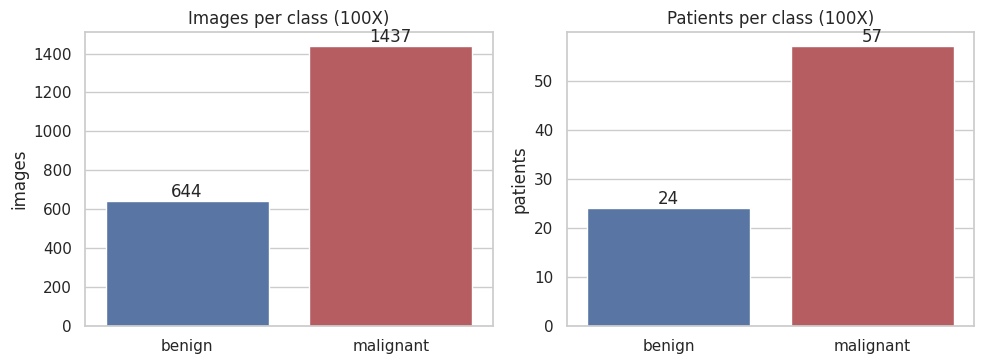

In [7]:
def image_stats(path: str) -> Dict[str, float]:
    with Image.open(path) as im:
        w, h = im.size
        mode = im.mode
        arr = np.asarray(im.convert('RGB'), dtype=np.float64) / 255.0
    flat = arr.reshape(-1, 3)
    return {'width': w, 'height': h, 'mode': mode, 'n_px': flat.shape[0],
            'sum_r': flat[:, 0].sum(), 'sum_g': flat[:, 1].sum(), 'sum_b': flat[:, 2].sum(),
            'sq_r': (flat[:, 0] ** 2).sum(), 'sq_g': (flat[:, 1] ** 2).sum(), 'sq_b': (flat[:, 2] ** 2).sum()}


stats_df = pd.DataFrame([image_stats(p) for p in tqdm(df['path'], desc='Image statistics')])
stats_df['label'] = df['label'].values


def pooled_rgb(sub: pd.DataFrame) -> Dict[str, List[float]]:
    n = sub['n_px'].sum()
    mean = [sub[f'sum_{c}'].sum() / n for c in 'rgb']
    std = [math.sqrt(max(sub[f'sq_{c}'].sum() / n - m ** 2, 0.0)) for c, m in zip('rgb', mean)]
    return {'mean': [round(v, 4) for v in mean], 'std': [round(v, 4) for v in std]}


size_counts = (stats_df.groupby(['width', 'height']).size().sort_values(ascending=False))
TRAINING_IMAGE_SIZES = [{'width': int(w), 'height': int(h), 'count': int(c)}
                        for (w, h), c in size_counts.items()]
print('Image sizes (width x height: count):')
for s in TRAINING_IMAGE_SIZES[:10]:
    print(f"  {s['width']}x{s['height']}: {s['count']}")
print('Colour modes:', stats_df['mode'].value_counts().to_dict())

subtype_table = (df.groupby(['label', 'subtype'])
                   .agg(images=('path', 'size'), patients=('patient_id', 'nunique'))
                   .reset_index())
subtype_table['subtype_name'] = subtype_table['subtype'].map(SUBTYPE_NAMES)
display(subtype_table)

DATASET_STATS = {
    'dataset': 'BreakHis (Breast Cancer Histopathological Database)',
    'dataset_url': BREAKHIS_URL,
    'magnification': MAGNIFICATION,
    'stain': 'H&E',
    'note': 'Descriptive statistics for display only. Model input normalisation uses ImageNet '
            'mean/std - see model_config.json -> preprocessing.normalize.',
    'n_images': int(len(df)),
    'n_patients': int(df['patient_id'].nunique()),
    'classes': {
        cls: {'images': int((df['label'] == cls).sum()),
              'patients': int(df.loc[df['label'] == cls, 'patient_id'].nunique()),
              'image_fraction': round(float((df['label'] == cls).mean()), 4)}
        for cls in CLASSES
    },
    'subtypes': [
        {'class': r.label, 'code': r.subtype, 'name': r.subtype_name,
         'images': int(r.images), 'patients': int(r.patients)}
        for r in subtype_table.itertuples()
    ],
    'image_sizes': TRAINING_IMAGE_SIZES,
    'colour_modes': {k: int(v) for k, v in stats_df['mode'].value_counts().items()},
    'rgb_0_1': {'all': pooled_rgb(stats_df),
                **{cls: pooled_rgb(stats_df[stats_df['label'] == cls]) for cls in CLASSES}},
    'integrity': {
        'unparsed_filenames': 0,
        'patients_in_both_classes': 0,
        'patients_spanning_subtypes': {k: v for k, v in multi_subtype_patients.items()},
        'files_with_other_magnification_in_name': int(len(mag_mismatch)),
        'identical_content_images': int(df['md5'].duplicated(keep=False).sum()),
        'identical_content_groups_across_patients': int(len(cross_patient_dups)),
    },
}


def save_fig(fig, name: str) -> Path:
    path = ARTIFACT_DIR / name
    fig.savefig(path, dpi=150, bbox_inches='tight')
    return path


fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
counts = df.groupby('label').agg(images=('path', 'size'), patients=('patient_id', 'nunique'))
for ax, col in zip(axes, ['images', 'patients']):
    sns.barplot(x=counts.index, y=counts[col], ax=ax, palette=['#4C72B0', '#C44E52'])
    ax.set_title(f'{col.capitalize()} per class ({MAGNIFICATION})')
    ax.set_xlabel('')
    ax.set_ylabel(col)
    for i, v in enumerate(counts[col]):
        ax.text(i, v, str(v), ha='center', va='bottom')
plt.tight_layout()
save_fig(fig, 'class_distribution.png')
plt.show()

## 6. Preprocessing: one definition for training and the app

The evaluation transform is written once as the `PREPROCESSING` dictionary, saved in `model_config.json`, and rebuilt from that dictionary by `build_eval_transform()`. The app will use the same function, so preprocessing in training and in deployment cannot drift apart.

The method is the one the study used: **`Resize((224, 224))` squash** (aspect ratio not preserved, no centre crop), bilinear interpolation, then ImageNet normalisation. timm's own pretrained evaluation pipeline for Swin uses bicubic resize and a 0.9 centre crop. It is deliberately **not** used here, because the weights are fine-tuned on the pipeline below.

In [8]:
IMAGENET_MEAN = [float(v) for v in IMAGENET_DEFAULT_MEAN]
IMAGENET_STD = [float(v) for v in IMAGENET_DEFAULT_STD]

PREPROCESSING = {
    'decode': "PIL.Image.open(file).convert('RGB')  (RGBA/LA/P/L/CMYK -> RGB; alpha is dropped, not composited)",
    'resize': {
        'method': 'squash',
        'op': 'torchvision.transforms.Resize(size=(H, W))',
        'size_hw': [IMAGE_SIZE, IMAGE_SIZE],
        'interpolation': 'bilinear',
        'antialias': True,
        'preserves_aspect_ratio': False,
    },
    'center_crop': None,
    'to_tensor': 'torchvision.transforms.ToTensor(): HWC uint8 [0,255] -> CHW float32 [0,1]',
    'normalize': {
        'mean': IMAGENET_MEAN,
        'std': IMAGENET_STD,
        'source': 'ImageNet (timm IMAGENET_DEFAULT_MEAN / IMAGENET_DEFAULT_STD)',
        'note': 'Dataset statistics in dataset_stats.json are for display only and are NOT used here.',
    },
    'channel_order': 'RGB',
    'tensor_layout': 'NCHW',
    'dtype': 'float32',
}

TRAIN_AUGMENTATION = [
    'RandomHorizontalFlip(p=0.5)', 'RandomVerticalFlip(p=0.5)', 'RandomRotation(20)',
    'ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1)',
]

_INTERPOLATION = {'bilinear': T.InterpolationMode.BILINEAR,
                  'bicubic': T.InterpolationMode.BICUBIC,
                  'nearest': T.InterpolationMode.NEAREST}


def build_resize(pp: Dict) -> T.Resize:
    r = pp['resize']
    if r['method'] != 'squash' or pp.get('center_crop') is not None:
        raise ValueError(f'Unsupported preprocessing: {r["method"]}, crop={pp.get("center_crop")}')
    return T.Resize(tuple(r['size_hw']), interpolation=_INTERPOLATION[r['interpolation']],
                    antialias=r['antialias'])


def build_eval_transform(pp: Dict) -> T.Compose:
    """Exact inference preprocessing. The app must call this with model_config['preprocessing']."""
    return T.Compose([build_resize(pp), T.ToTensor(),
                      T.Normalize(pp['normalize']['mean'], pp['normalize']['std'])])


def build_train_transform(pp: Dict) -> T.Compose:
    return T.Compose([
        build_resize(pp),
        T.RandomHorizontalFlip(), T.RandomVerticalFlip(), T.RandomRotation(20),
        T.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
        T.ToTensor(),
        T.Normalize(pp['normalize']['mean'], pp['normalize']['std']),
    ])


def load_rgb(path: str) -> Image.Image:
    with Image.open(path) as im:
        return im.convert('RGB')


EVAL_TRANSFORM = build_eval_transform(PREPROCESSING)
TRAIN_TRANSFORM = build_train_transform(PREPROCESSING)

_probe = timm.create_model(TIMM_MODEL_NAME, pretrained=False, num_classes=2)
_timm_cfg = timm.data.resolve_data_config({}, model=_probe)
print('timm pretrained config (for reference, not used):', _timm_cfg)
assert np.allclose(_timm_cfg['mean'], IMAGENET_MEAN) and np.allclose(_timm_cfg['std'], IMAGENET_STD), \
    'Swin pretrained normalisation is not ImageNet mean/std - review PREPROCESSING.'
del _probe
print('Eval transform:', EVAL_TRANSFORM)

timm pretrained config (for reference, not used): {'input_size': (3, 224, 224), 'interpolation': 'bicubic', 'mean': (0.485, 0.456, 0.406), 'std': (0.229, 0.224, 0.225), 'crop_pct': 0.9, 'crop_mode': 'center'}
Eval transform: Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


## 7. Training and evaluation utilities

The training loop is the study's: AdamW, cosine schedule, mixed precision, and early stopping on validation loss that restores the weights from the epoch with the lowest validation loss. Probabilities are computed in float32 without autocast, to match what the CPU app computes.

**Threshold rule.** The model predicts *malignant* if `p_malignant >= t`. On the validation set, `t` is the **highest** threshold that keeps validation malignant recall ≥ `TARGET_MALIGNANT_RECALL`. Picking the highest such value keeps as many benign images as possible correctly classified while meeting the recall target.

In [9]:
class HistopathologyDataset(Dataset):
    def __init__(self, frame: pd.DataFrame, transform: Callable):
        self.paths = frame['path'].tolist()
        self.labels = frame['y'].astype(int).tolist()
        self.transform = transform

    def __len__(self) -> int:
        return len(self.paths)

    def __getitem__(self, idx: int):
        return self.transform(load_rgb(self.paths[idx])), self.labels[idx]


def _seed_worker(worker_id: int) -> None:
    s = torch.initial_seed() % 2 ** 32
    np.random.seed(s)
    random.seed(s)


def make_loader(frame: pd.DataFrame, train: bool, seed: int) -> DataLoader:
    g = torch.Generator()
    g.manual_seed(seed)
    return DataLoader(
        HistopathologyDataset(frame, TRAIN_TRANSFORM if train else EVAL_TRANSFORM),
        batch_size=BATCH_SIZE, shuffle=train, num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == 'cuda'), worker_init_fn=_seed_worker, generator=g,
    )


class ValidationLossEarlyStopping:
    """Patience counts significant improvements; weights are kept at the absolute minimum loss."""

    def __init__(self, patience: int, min_delta: float):
        self.patience, self.min_delta = patience, min_delta
        self.reference_loss = self.best_loss = float('inf')
        self.best_state, self.best_epoch, self.bad_epochs = None, None, 0

    def update(self, val_loss: float, model: nn.Module, epoch: int) -> bool:
        if not np.isfinite(val_loss):
            raise RuntimeError('Validation loss is non-finite.')
        if val_loss < self.best_loss:
            self.best_loss, self.best_epoch = val_loss, epoch
            self.best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        if val_loss < self.reference_loss - self.min_delta:
            self.reference_loss, self.bad_epochs = val_loss, 0
        else:
            self.bad_epochs += 1
        return self.bad_epochs >= self.patience

    def restore(self, model: nn.Module) -> None:
        model.load_state_dict(self.best_state)


def build_model(pretrained: bool = True) -> nn.Module:
    return timm.create_model(TIMM_MODEL_NAME, pretrained=pretrained, num_classes=len(CLASSES))


def train_model(model: nn.Module, train_loader: DataLoader, val_loader: DataLoader,
                run_name: str) -> Tuple[nn.Module, Dict]:
    model = model.to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)
    criterion = nn.CrossEntropyLoss()
    use_amp = DEVICE.type == 'cuda'
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    stopper = ValidationLossEarlyStopping(EARLY_STOPPING_PATIENCE, EARLY_STOPPING_MIN_DELTA)
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    stopped_early = False

    for epoch in range(1, NUM_EPOCHS + 1):
        model.train()
        tot_loss, tot_correct, n = 0.0, 0, 0
        for imgs, labels in tqdm(train_loader, desc=f'[{run_name}] epoch {epoch}/{NUM_EPOCHS}', leave=False):
            imgs, labels = imgs.to(DEVICE, non_blocking=True), labels.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
                out = model(imgs)
                loss = criterion(out, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            tot_loss += loss.item() * imgs.size(0)
            tot_correct += (out.argmax(1) == labels).sum().item()
            n += imgs.size(0)

        model.eval()
        v_loss, v_correct, vn = 0.0, 0, 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
                out = model(imgs)
                v_loss += criterion(out, labels).item() * imgs.size(0)
                v_correct += (out.argmax(1) == labels).sum().item()
                vn += imgs.size(0)
        scheduler.step()

        history['train_loss'].append(tot_loss / n)
        history['train_acc'].append(tot_correct / n)
        history['val_loss'].append(v_loss / vn)
        history['val_acc'].append(v_correct / vn)
        print(f'[{run_name}] epoch {epoch}: train_loss={tot_loss / n:.4f} train_acc={tot_correct / n:.4f} '
              f'val_loss={v_loss / vn:.4f} val_acc={v_correct / vn:.4f}')
        if stopper.update(v_loss / vn, model, epoch):
            stopped_early = True
            print(f'[{run_name}] early stopping at epoch {epoch}')
            break

    stopper.restore(model)
    summary = {'best_epoch': stopper.best_epoch, 'best_val_loss': float(stopper.best_loss),
               'epochs_run': len(history['val_loss']), 'stopped_early': stopped_early,
               'history': history}
    print(f'[{run_name}] restored epoch {stopper.best_epoch} (val_loss={stopper.best_loss:.5f})')
    return model, summary


@torch.no_grad()
def predict_proba(model: nn.Module, loader: DataLoader) -> Tuple[np.ndarray, np.ndarray]:
    """Return (y_true, p_malignant). float32 forward pass, softmax in float64."""
    model.eval()
    ys, ps = [], []
    for imgs, labels in loader:
        logits = model(imgs.to(DEVICE)).double()
        ps.append(torch.softmax(logits, dim=1)[:, LABEL_MAP['malignant']].cpu().numpy())
        ys.append(labels.numpy())
    return np.concatenate(ys), np.concatenate(ps)


def select_threshold_for_recall(y_true: np.ndarray, p: np.ndarray, target_recall: float) -> Dict:
    """Highest t such that recall(p >= t) on positives is >= target_recall."""
    pos = np.sort(p[y_true == 1])
    if len(pos) == 0 or (y_true == 0).sum() == 0:
        raise ValueError('Validation set must contain both classes.')
    k = int(math.ceil(target_recall * len(pos) - 1e-12))   # positives that must be >= t
    t = float(pos[len(pos) - k])
    pred = (p >= t).astype(int)
    return {
        'threshold': t,
        'target_malignant_recall': target_recall,
        'val_malignant_recall': float(recall_score(y_true, pred, pos_label=1)),
        'val_benign_recall': float(recall_score(y_true, pred, pos_label=0)),
        'val_n_malignant': int(len(pos)), 'val_n_benign': int((y_true == 0).sum()),
    }


def compute_metrics(y_true: np.ndarray, p: np.ndarray, threshold: float) -> Dict[str, float]:
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    both = len(np.unique(y_true)) == 2
    return {
        'threshold': float(threshold),
        'accuracy': float(accuracy_score(y_true, pred)),
        'balanced_accuracy': float(balanced_accuracy_score(y_true, pred)),
        'malignant_recall': float(tp / (tp + fn)) if tp + fn else float('nan'),
        'benign_recall': float(tn / (tn + fp)) if tn + fp else float('nan'),
        'malignant_precision': float(precision_score(y_true, pred, pos_label=1, zero_division=0)),
        'malignant_f1': float(f1_score(y_true, pred, pos_label=1, zero_division=0)),
        'weighted_f1': float(f1_score(y_true, pred, average='weighted', zero_division=0)),
        'roc_auc': float(roc_auc_score(y_true, p)) if both else float('nan'),
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp), 'n': int(len(y_true)),
    }


def stratified_group_holdout(frame: pd.DataFrame, fraction: float, seed: int
                             ) -> Tuple[pd.DataFrame, pd.DataFrame]:
    """Patient-grouped, class-stratified holdout. Takes the first fold with enough patients of each class."""
    n_splits = max(2, int(round(1 / fraction)))
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for keep_idx, hold_idx in sgkf.split(frame, frame['y'], frame['patient_id']):
        hold = frame.iloc[hold_idx]
        per_class = hold.groupby('y')['patient_id'].nunique()
        if len(per_class) == 2 and per_class.min() >= MIN_VAL_PATIENTS_PER_CLASS:
            return frame.iloc[keep_idx].reset_index(drop=True), hold.reset_index(drop=True)
    raise RuntimeError('No holdout fold had enough patients of both classes.')


def assert_disjoint_patients(**parts: pd.DataFrame) -> None:
    names = list(parts)
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            shared = set(parts[names[i]]['patient_id']) & set(parts[names[j]]['patient_id'])
            if shared:
                raise AssertionError(f'Patients shared by {names[i]} and {names[j]}: {sorted(shared)}')


def describe_split(**parts: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for name, part in parts.items():
        for cls in CLASSES:
            sub = part[part['label'] == cls]
            rows.append({'split': name, 'class': cls, 'patients': sub['patient_id'].nunique(),
                         'images': len(sub)})
    return pd.DataFrame(rows).pivot(index='split', columns='class', values=['patients', 'images'])


def plot_history(history: Dict, title: str):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    ep = range(1, len(history['train_loss']) + 1)
    for ax, key in zip(axes, ['loss', 'acc']):
        ax.plot(ep, history[f'train_{key}'], marker='o', label='train')
        ax.plot(ep, history[f'val_{key}'], marker='o', label='validation')
        ax.set_title(f'{title} - {key}')
        ax.set_xlabel('epoch')
        ax.legend()
    plt.tight_layout()
    return fig


def run_experiment(train_df: pd.DataFrame, val_df: pd.DataFrame, test_df: Optional[pd.DataFrame],
                   run_name: str, seed: int) -> Dict:
    """Train on train_df, early-stop and pick the threshold on val_df, evaluate on test_df."""
    seed_everything(seed)
    model = build_model(pretrained=True)
    model, summary = train_model(model, make_loader(train_df, True, seed),
                                 make_loader(val_df, False, seed), run_name)
    y_val, p_val = predict_proba(model, make_loader(val_df, False, seed))
    thr = select_threshold_for_recall(y_val, p_val, TARGET_MALIGNANT_RECALL)
    out = {'run': run_name, 'training': summary, 'threshold_selection': thr,
           'val_at_selected': compute_metrics(y_val, p_val, thr['threshold']),
           'model': model}
    if test_df is not None:
        y_te, p_te = predict_proba(model, make_loader(test_df, False, seed))
        out.update({'y_test': y_te, 'p_test': p_te,
                    'test_at_selected': compute_metrics(y_te, p_te, thr['threshold']),
                    'test_at_0.5': compute_metrics(y_te, p_te, REFERENCE_THRESHOLD)})
        print(f"[{run_name}] t={thr['threshold']:.4f} | test@t: "
              f"mal_recall={out['test_at_selected']['malignant_recall']:.3f} "
              f"ben_recall={out['test_at_selected']['benign_recall']:.3f} "
              f"bal_acc={out['test_at_selected']['balanced_accuracy']:.3f} "
              f"auc={out['test_at_selected']['roc_auc']:.4f}")
    return out


def release(result: Dict) -> None:
    """Drop the model from a result dict to free GPU memory."""
    result.pop('model', None)
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

## 8. Patient-level cross-validation (the headline estimate)

The outer `StratifiedGroupKFold` assigns every patient to exactly one test fold. Within each fold's training patients, a further patient-grouped holdout of about 15% is used as the validation set, for early stopping and for choosing the threshold. Patient and image counts are printed for every split, and the patient sets are asserted to be disjoint.


========== Fold 1/5 ==========


patients           images          
class   benign malignant benign malignant
split                                    
test         2        14     50       359
train       19        37    520       901
val          3         6     74       177

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

[fold1] epoch 1/10:   0%|          | 0/45 [00:00<?, ?it/s]

[fold1] epoch 1: train_loss=0.3041 train_acc=0.8649 val_loss=0.4315 val_acc=0.7888


... (5 outputs left out)

[fold1] epoch 4/10:   0%|          | 0/45 [00:00<?, ?it/s]

[fold1] epoch 4: train_loss=0.0805 train_acc=0.9697 val_loss=0.2282 val_acc=0.9562


[fold1] epoch 5/10:   0%|          | 0/45 [00:00<?, ?it/s]

[fold1] epoch 5: train_loss=0.0253 train_acc=0.9887 val_loss=0.2685 val_acc=0.9283
[fold1] early stopping at epoch 5
[fold1] restored epoch 2 (val_loss=0.22037)
[fold1] t=0.1381 | test@t: mal_recall=1.000 ben_recall=0.560 bal_acc=0.780 auc=0.9825


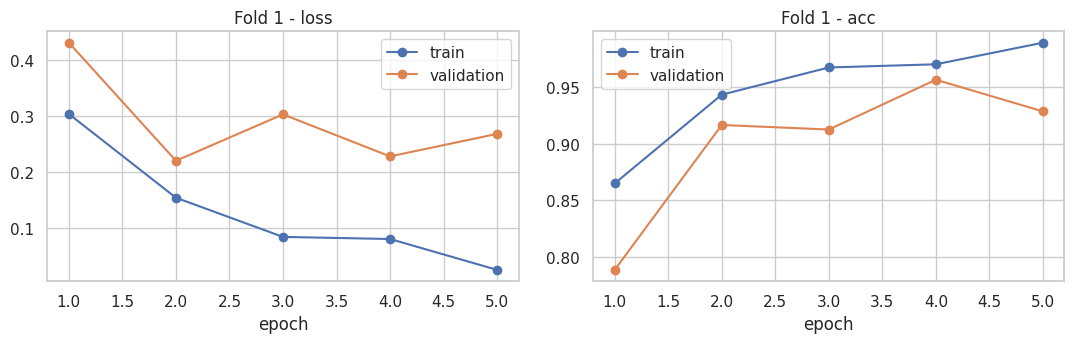


========== Fold 2/5 ==========


patients           images          
class   benign malignant benign malignant
split                                    
test         4        12    100       335
train       18        39    464       953
val          2         6     80       149

[fold2] epoch 1/10:   0%|          | 0/45 [00:00<?, ?it/s]

[fold2] epoch 1: train_loss=0.3689 train_acc=0.8497 val_loss=0.3865 val_acc=0.8690


[fold2] epoch 2/10:   0%|          | 0/45 [00:00<?, ?it/s]

[fold2] epoch 2: train_loss=0.1437 train_acc=0.9442 val_loss=0.3558 val_acc=0.9083


... (4 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f87bd5bfb00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f87bd5bfb00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

[fold2] epoch 4: train_loss=0.0821 train_acc=0.9718 val_loss=0.5491 val_acc=0.8734


[fold2] epoch 5/10:   0%|          | 0/45 [00:00<?, ?it/s]

[fold2] epoch 5: train_loss=0.0403 train_acc=0.9845 val_loss=0.5878 val_acc=0.8952
[fold2] early stopping at epoch 5
[fold2] restored epoch 2 (val_loss=0.35577)
[fold2] t=0.8565 | test@t: mal_recall=0.824 ben_recall=0.980 bal_acc=0.902 auc=0.9695


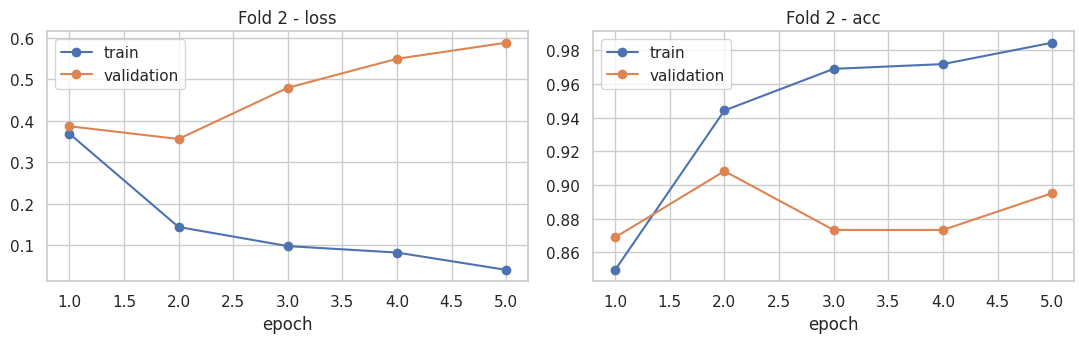


========== Fold 3/5 ==========


patients           images          
class   benign malignant benign malignant
split                                    
test         4        13     99       298
train       16        39    462      1003
val          4         5     83       136

[fold3] epoch 1/10:   0%|          | 0/46 [00:00<?, ?it/s]

[fold3] epoch 1: train_loss=0.4954 train_acc=0.7693 val_loss=0.3923 val_acc=0.9178


[fold3] epoch 2/10:   0%|          | 0/46 [00:00<?, ?it/s]

[fold3] epoch 2: train_loss=0.2325 train_acc=0.9044 val_loss=0.1920 val_acc=0.9041


... (15 outputs left out)

[fold3] epoch 8: train_loss=0.0163 train_acc=0.9939 val_loss=0.2897 val_acc=0.9406


[fold3] epoch 9/10:   0%|          | 0/46 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f87bd5bfb00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
self._shutdown_workers()    
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():Exception ignored in: 
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    <function _MultiProcessingDataLoaderIter.__del__ at 0x7f87bd5bfb00>
assert self._parent_pid == os.getpid(), 'can only test a child process'
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
AssertionError    : self._shutdown_workers()can only test a child process

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
Exception ignored in: <function _Multi

[fold3] epoch 9: train_loss=0.0082 train_acc=0.9980 val_loss=0.1822 val_acc=0.9315
[fold3] early stopping at epoch 9
[fold3] restored epoch 6 (val_loss=0.10764)
[fold3] t=0.4003 | test@t: mal_recall=0.956 ben_recall=0.899 bal_acc=0.928 auc=0.9797


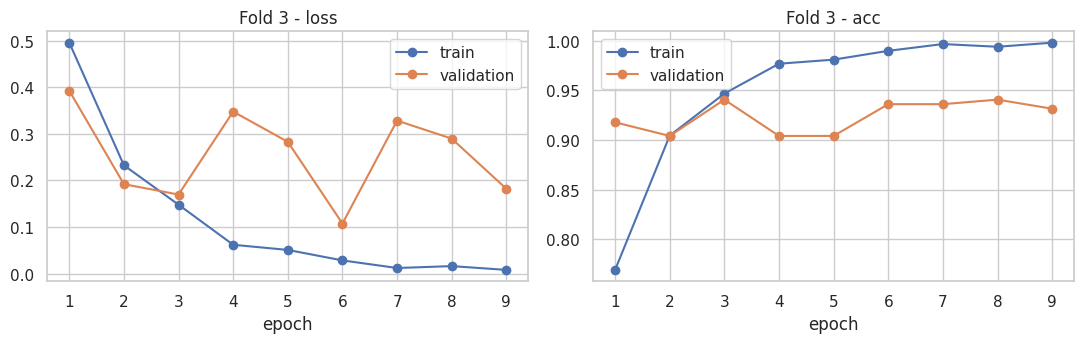


========== Fold 4/5 ==========


patients           images          
class   benign malignant benign malignant
split                                    
test         5        11    147       284
train       16        41    410      1043
val          3         5     87       110

[fold4] epoch 1/10:   0%|          | 0/46 [00:00<?, ?it/s]

[fold4] epoch 1: train_loss=0.2934 train_acc=0.8858 val_loss=0.4774 val_acc=0.8122


[fold4] epoch 2/10:   0%|          | 0/46 [00:00<?, ?it/s]

[fold4] epoch 2: train_loss=0.1183 train_acc=0.9546 val_loss=0.3760 val_acc=0.8832


... (7 outputs left out)

[fold4] epoch 5: train_loss=0.0416 train_acc=0.9883 val_loss=0.3040 val_acc=0.9137


[fold4] epoch 6/10:   0%|          | 0/46 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f87bd5bfb00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f87bd5bfb00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

[fold4] epoch 6: train_loss=0.0338 train_acc=0.9911 val_loss=0.5551 val_acc=0.9239
[fold4] early stopping at epoch 6
[fold4] restored epoch 3 (val_loss=0.25413)
[fold4] t=0.0694 | test@t: mal_recall=0.947 ben_recall=0.551 bal_acc=0.749 auc=0.9050


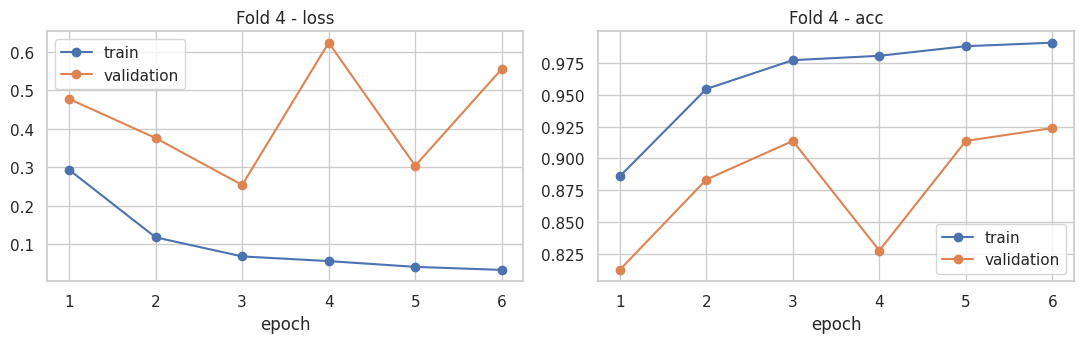


========== Fold 5/5 ==========


patients           images          
class   benign malignant benign malignant
split                                    
test         9         7    248       161
train       13        42    346      1090
val          2         8     50       186

[fold5] epoch 1/10:   0%|          | 0/45 [00:00<?, ?it/s]

[fold5] epoch 1: train_loss=0.2979 train_acc=0.8781 val_loss=0.3079 val_acc=0.8729


[fold5] epoch 2/10:   0%|          | 0/45 [00:00<?, ?it/s]

[fold5] epoch 2: train_loss=0.1439 train_acc=0.9513 val_loss=0.0600 val_acc=0.9873


... (15 outputs left out)

[fold5] epoch 8: train_loss=0.0096 train_acc=0.9965 val_loss=0.0332 val_acc=0.9788


[fold5] epoch 9/10:   0%|          | 0/45 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f87bd5bfb00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f87bd5bfb00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

[fold5] epoch 9: train_loss=0.0052 train_acc=0.9993 val_loss=0.0267 val_acc=0.9915
[fold5] early stopping at epoch 9
[fold5] restored epoch 6 (val_loss=0.01098)
[fold5] t=0.9841 | test@t: mal_recall=0.963 ben_recall=0.895 bal_acc=0.929 auc=0.9708


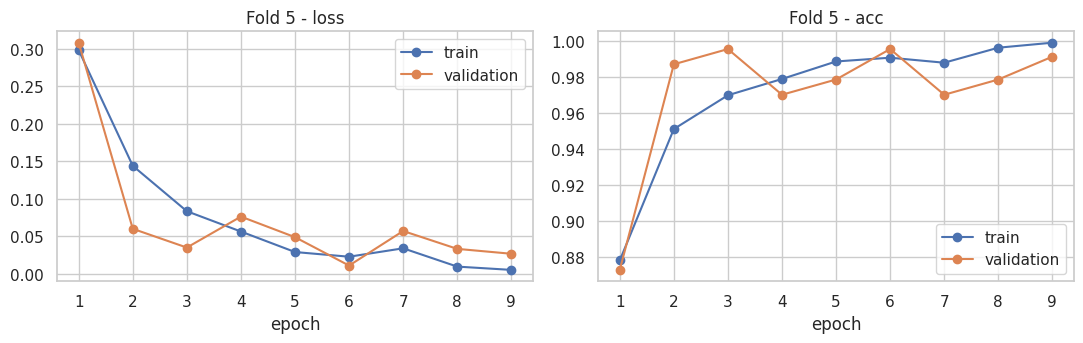

In [10]:
outer = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
cv_results, split_rows = [], []

for fold, (trv_idx, te_idx) in enumerate(outer.split(df, df['y'], df['patient_id'])):
    trv_df = df.iloc[trv_idx].reset_index(drop=True)
    te_df = df.iloc[te_idx].reset_index(drop=True)
    tr_df, va_df = stratified_group_holdout(trv_df, INNER_VAL_FRACTION, SEED + fold)
    assert_disjoint_patients(train=tr_df, val=va_df, test=te_df)

    print(f'\n========== Fold {fold + 1}/{N_FOLDS} ==========')
    display(describe_split(train=tr_df, val=va_df, test=te_df))
    for name, part in [('train', tr_df), ('val', va_df), ('test', te_df)]:
        split_rows += [{'protocol': 'patient_cv', 'fold': fold, 'split': name,
                        'filename': f, 'patient_id': p, 'label': l}
                       for f, p, l in zip(part['filename'], part['patient_id'], part['label'])]

    res = run_experiment(tr_df, va_df, te_df, f'fold{fold + 1}', SEED + fold)
    res['fold'] = fold
    res['test_patients'] = sorted(te_df['patient_id'].unique().tolist())
    fig = plot_history(res['training']['history'], f'Fold {fold + 1}')
    plt.show()
    release(res)
    cv_results.append(res)

Patient-level 5-fold CV, test folds (mean ± std across folds)


,at selected threshold,at 0.5 (reference)
accuracy,0.8964 ± 0.0584,0.9105 ± 0.0407
balanced_accuracy,0.8575 ± 0.0863,0.8859 ± 0.0430
malignant_recall,0.9380 ± 0.0669,0.9453 ± 0.0418
benign_recall,0.7770 ± 0.2051,0.8265 ± 0.0935
malignant_precision,0.9121 ± 0.0796,0.9159 ± 0.0780
malignant_f1,0.9215 ± 0.0429,0.9283 ± 0.0436
weighted_f1,0.8946 ± 0.0605,0.9109 ± 0.0400
roc_auc,0.9615 ± 0.0321,0.9615 ± 0.0321


Per-fold selected thresholds: [0.1381, 0.8565, 0.4003, 0.0694, 0.9841]


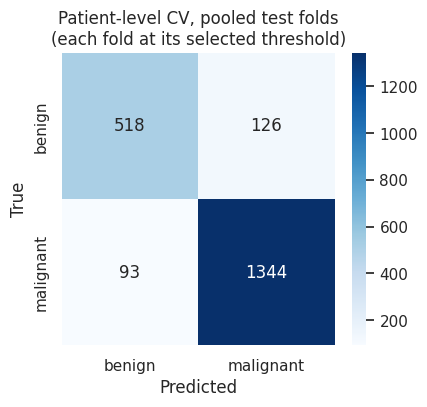

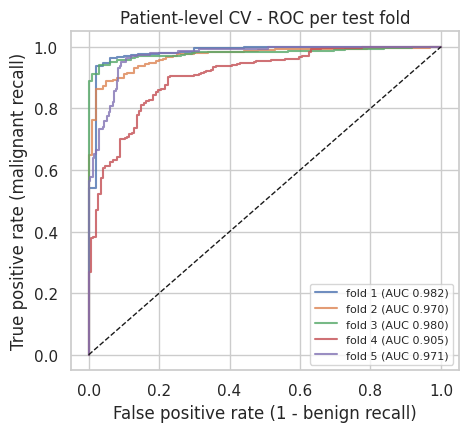

In [11]:
METRIC_KEYS = ['accuracy', 'balanced_accuracy', 'malignant_recall', 'benign_recall',
               'malignant_precision', 'malignant_f1', 'weighted_f1', 'roc_auc']


def summarise(results: List[Dict], key: str) -> Dict[str, Dict[str, float]]:
    table = pd.DataFrame([r[key] for r in results])
    return {m: {'mean': float(table[m].mean()), 'std': float(table[m].std(ddof=1)),
                'per_fold': [float(v) for v in table[m]]} for m in METRIC_KEYS}


cv_selected = summarise(cv_results, 'test_at_selected')
cv_half = summarise(cv_results, 'test_at_0.5')
fold_thresholds = [r['threshold_selection']['threshold'] for r in cv_results]

summary_table = pd.DataFrame({
    f'at selected threshold': {m: f"{v['mean']:.4f} ± {v['std']:.4f}" for m, v in cv_selected.items()},
    'at 0.5 (reference)': {m: f"{v['mean']:.4f} ± {v['std']:.4f}" for m, v in cv_half.items()},
})
print(f'Patient-level {N_FOLDS}-fold CV, test folds (mean ± std across folds)')
display(summary_table)
print('Per-fold selected thresholds:', [round(t, 4) for t in fold_thresholds])

# Pooled out-of-fold confusion matrix (each fold scored at its own selected threshold) and ROC.
oof_y = np.concatenate([r['y_test'] for r in cv_results])
oof_pred = np.concatenate([(r['p_test'] >= r['threshold_selection']['threshold']).astype(int)
                           for r in cv_results])
oof_cm = confusion_matrix(oof_y, oof_pred, labels=[0, 1])

fig, ax = plt.subplots(figsize=(4.4, 3.8))
sns.heatmap(oof_cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
ax.set_title(f'Patient-level CV, pooled test folds\n(each fold at its selected threshold)')
save_fig(fig, 'cv_confusion_matrix.png')
plt.show()

fig, ax = plt.subplots(figsize=(5, 4.4))
for r in cv_results:
    fpr, tpr, _ = roc_curve(r['y_test'], r['p_test'])
    ax.plot(fpr, tpr, alpha=0.8, label=f"fold {r['fold'] + 1} (AUC {r['test_at_selected']['roc_auc']:.3f})")
ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.set_xlabel('False positive rate (1 - benign recall)')
ax.set_ylabel('True positive rate (malignant recall)')
ax.set_title('Patient-level CV - ROC per test fold')
ax.legend(fontsize=8)
save_fig(fig, 'cv_roc_curve.png')
plt.show()

### Interpretation guide

* Compare **malignant recall at the selected threshold** with the 0.95 target. The threshold was fitted on a small validation set (a few patients per class), so test recall can fall below the target. The spread across folds shows how much it does.
* Balanced accuracy and benign recall show what the recall constraint costs on the benign class.
* A large standard deviation means the result depends strongly on which patients end up in the test fold. With about 16 test patients per fold, that is expected.

## 9. Leakage-prone baseline (original image-level split)

This reproduces the study's split: stratified by image, 70/15/15, seed 42. It uses the same training procedure and threshold rule as above. The count of test patients that also appear in training shows how much the split leaks. **These numbers are not used by the app.**

In [12]:
baseline = None
if RUN_LEAKAGE_BASELINE:
    trv_img, te_img = train_test_split(df, test_size=0.15, stratify=df['label'], random_state=SEED)
    tr_img, va_img = train_test_split(trv_img, test_size=0.15 / 0.85, stratify=trv_img['label'],
                                      random_state=SEED)
    tr_img, va_img, te_img = (x.reset_index(drop=True) for x in (tr_img, va_img, te_img))

    test_patients = set(te_img['patient_id'])
    leaked = test_patients & set(tr_img['patient_id'])
    leaked_images = int(te_img['patient_id'].isin(tr_img['patient_id']).sum())
    print(f'Image-level split: {len(tr_img)}/{len(va_img)}/{len(te_img)} images')
    print(f'Test patients also in training: {len(leaked)} of {len(test_patients)}; '
          f'test images from those patients: {leaked_images} of {len(te_img)}')
    display(describe_split(train=tr_img, val=va_img, test=te_img))
    for name, part in [('train', tr_img), ('val', va_img), ('test', te_img)]:
        split_rows += [{'protocol': 'image_level_baseline', 'fold': -1, 'split': name,
                        'filename': f, 'patient_id': p, 'label': l}
                       for f, p, l in zip(part['filename'], part['patient_id'], part['label'])]

    baseline = run_experiment(tr_img, va_img, te_img, 'image-level baseline', SEED)
    release(baseline)
    baseline['leakage'] = {'test_patients': len(test_patients),
                           'test_patients_also_in_train': len(leaked),
                           'test_images_from_leaked_patients': leaked_images,
                           'test_images': int(len(te_img))}

    cmp = pd.DataFrame({
        'patient-level CV (mean)': {m: cv_selected[m]['mean'] for m in METRIC_KEYS},
        'leakage-prone baseline': {m: baseline['test_at_selected'][m] for m in METRIC_KEYS},
    }).round(4)
    print('Both at their validation-selected thresholds:')
    display(cmp)

Image-level split: 1456/312/313 images
Test patients also in training: 78 of 78; test images from those patients: 313 of 313


patients           images          
class   benign malignant benign malignant
split                                    
test        24        54     97       216
train       24        57    450      1006
val         22        53     97       215

[image-level baseline] epoch 1/10:   0%|          | 0/46 [00:00<?, ?it/s]

[image-level baseline] epoch 1: train_loss=0.3755 train_acc=0.8276 val_loss=0.1616 val_acc=0.9295


[image-level baseline] epoch 2/10:   0%|          | 0/46 [00:00<?, ?it/s]

[image-level baseline] epoch 2: train_loss=0.2082 train_acc=0.9251 val_loss=0.0960 val_acc=0.9615


... (18 outputs left out)

[image-level baseline] epoch 10/10:   0%|          | 0/46 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f87bd5bfb00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f87bd5bfb00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

[image-level baseline] epoch 10: train_loss=0.0086 train_acc=0.9979 val_loss=0.0348 val_acc=0.9904
[image-level baseline] restored epoch 9 (val_loss=0.03289)
[image-level baseline] t=0.9968 | test@t: mal_recall=0.894 ben_recall=1.000 bal_acc=0.947 auc=0.9995
Both at their validation-selected thresholds:


,patient-level CV (mean),leakage-prone baseline
accuracy,0.8964,0.9265
balanced_accuracy,0.8575,0.9468
malignant_recall,0.9380,0.8935
benign_recall,0.7770,1.0000
malignant_precision,0.9121,1.0000
malignant_f1,0.9215,0.9438
weighted_f1,0.8946,0.9283
roc_auc,0.9615,0.9995


## 10. Final deployment model

The CV estimates how well the *training procedure* works on unseen patients. The deployed model is trained by that same procedure on all patients, minus a patient-grouped validation holdout of about 15%. The holdout is used for early stopping and for choosing the deployed threshold.

The deployed model has **no held-out test set of its own**. The performance quoted in the app is the patient-level CV estimate from Section 8, and `metrics.json` says so.

patients           images          
class   benign malignant benign malignant
split                                    
train       21        49    540      1199
val          3         8    104       238

[deployment] epoch 1/10:   0%|          | 0/55 [00:00<?, ?it/s]

[deployment] epoch 1: train_loss=0.3192 train_acc=0.8729 val_loss=0.4246 val_acc=0.8655


[deployment] epoch 2/10:   0%|          | 0/55 [00:00<?, ?it/s]

[deployment] epoch 2: train_loss=0.1615 train_acc=0.9373 val_loss=0.3798 val_acc=0.8947


[deployment] epoch 3/10:   0%|          | 0/55 [00:00<?, ?it/s]

... (8 outputs left out)

[deployment] epoch 6: train_loss=0.0179 train_acc=0.9954 val_loss=0.3801 val_acc=0.9327


[deployment] epoch 7/10:   0%|          | 0/55 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f87bd5bfb00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f87bd5bfb00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

[deployment] epoch 7: train_loss=0.0122 train_acc=0.9954 val_loss=0.3828 val_acc=0.9269
[deployment] early stopping at epoch 7
[deployment] restored epoch 4 (val_loss=0.26506)
Deployment threshold: 0.33991767471522394
Validation metrics at that threshold: {'threshold': 0.3399, 'accuracy': 0.924, 'balanced_accuracy': 0.9048, 'malignant_recall': 0.9538, 'benign_recall': 0.8558, 'malignant_precision': 0.938, 'malignant_f1': 0.9458, 'weighted_f1': 0.9235, 'roc_auc': 0.9753, 'tn': 89, 'fp': 15, 'fn': 11, 'tp': 227, 'n': 342}
(CV fold thresholds for comparison: [0.1381, 0.8565, 0.4003, 0.0694, 0.9841])


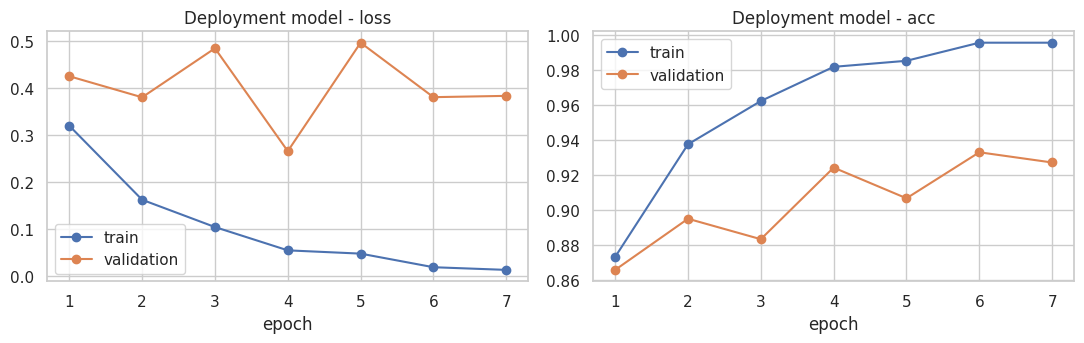

In [13]:
final_train_df, final_val_df = stratified_group_holdout(df, INNER_VAL_FRACTION, SEED)
assert_disjoint_patients(train=final_train_df, val=final_val_df)
display(describe_split(train=final_train_df, val=final_val_df))
for name, part in [('train', final_train_df), ('val', final_val_df)]:
    split_rows += [{'protocol': 'deployment', 'fold': -1, 'split': name,
                    'filename': f, 'patient_id': p, 'label': l}
                   for f, p, l in zip(part['filename'], part['patient_id'], part['label'])]

final = run_experiment(final_train_df, final_val_df, None, 'deployment', SEED)
final_model = final['model'].eval()
DEPLOY_THRESHOLD = final['threshold_selection']['threshold']
print('Deployment threshold:', DEPLOY_THRESHOLD)
print('Validation metrics at that threshold:',
      {k: round(v, 4) for k, v in final['val_at_selected'].items()})
print(f'(CV fold thresholds for comparison: {[round(t, 4) for t in fold_thresholds]})')

fig = plot_history(final['training']['history'], 'Deployment model')
save_fig(fig, 'training_history.png')
plt.show()

## 11. Grad-CAM verification. Stop here and look before exporting.

In timm ≥ 0.9, a `SwinTransformerBlock` takes and returns `(B, H, W, C)`. Inside the block, the tokens are flattened to `(B, H·W, C)` before `norm2`, so `norm2`'s output is **3-D** `(B, 49, C)` at the last stage. The target layer is therefore the **output of the last block**, `model.layers[-1].blocks[-1]`. The reshape transform accepts all three layouts: `(B, H, W, C)`, `(B, N, C)` and `(B, C, H, W)`. It refuses anything else rather than silently producing a wrong map.

The cell below prints the real shapes from this timm version, so nothing about the layout is assumed.

At 224×224 input, the last stage is a **7×7 grid**, one cell per 32×32-pixel region. The heatmap is upsampled from 7×7, so it is **coarse**: it shows which regions influenced the prediction, not individual cells or nuclei.

In [14]:
CAM_TARGET_LAYER_PATH = 'layers[-1].blocks[-1]'


def get_cam_target_layer(model: nn.Module) -> nn.Module:
    return model.layers[-1].blocks[-1]


def make_swin_reshape_transform(num_channels: int) -> Callable[[torch.Tensor], torch.Tensor]:
    """Convert a Swin activation/gradient to (B, C, H, W) for Grad-CAM."""
    def reshape_transform(t: torch.Tensor) -> torch.Tensor:
        if t.ndim == 4 and t.shape[-1] == num_channels:      # (B, H, W, C) - timm >= 0.9 block output
            return t.permute(0, 3, 1, 2).contiguous()
        if t.ndim == 4 and t.shape[1] == num_channels:       # already (B, C, H, W)
            return t
        if t.ndim == 3 and t.shape[-1] == num_channels:      # (B, N, C) - flattened tokens
            b, n, c = t.shape
            side = int(round(math.sqrt(n)))
            if side * side != n:
                raise ValueError(f'Token count {n} is not a square grid.')
            return t.reshape(b, side, side, c).permute(0, 3, 1, 2).contiguous()
        raise ValueError(f'Unexpected activation shape {tuple(t.shape)} for C={num_channels}.')
    return reshape_transform


# ---- Print the real shapes from this timm version ----
target_layer = get_cam_target_layer(final_model)
shapes = {}
hooks = [
    target_layer.register_forward_hook(lambda m, i, o: shapes.__setitem__('block output', tuple(o.shape))),
    target_layer.norm2.register_forward_hook(lambda m, i, o: shapes.__setitem__('block.norm2 output', tuple(o.shape))),
    final_model.norm.register_forward_hook(lambda m, i, o: shapes.__setitem__('model.norm output', tuple(o.shape))),
]
with torch.no_grad():
    final_model(torch.zeros(1, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE))
for h in hooks:
    h.remove()
for k, v in shapes.items():
    print(f'{k:>20}: {v}')

NUM_FEATURES = final_model.num_features
swin_reshape = make_swin_reshape_transform(NUM_FEATURES)
cam_input_shape = shapes['block output']
cam_grid = tuple(swin_reshape(torch.zeros(cam_input_shape)).shape[-2:])
print(f'num_features={NUM_FEATURES}; Grad-CAM grid after reshape: {cam_grid}')
assert cam_grid == (IMAGE_SIZE // 32, IMAGE_SIZE // 32), f'Unexpected CAM grid {cam_grid}'

  block.norm2 output: (1, 49, 768)
        block output: (1, 7, 7, 768)
   model.norm output: (1, 7, 7, 768)
num_features=768; Grad-CAM grid after reshape: (7, 7)


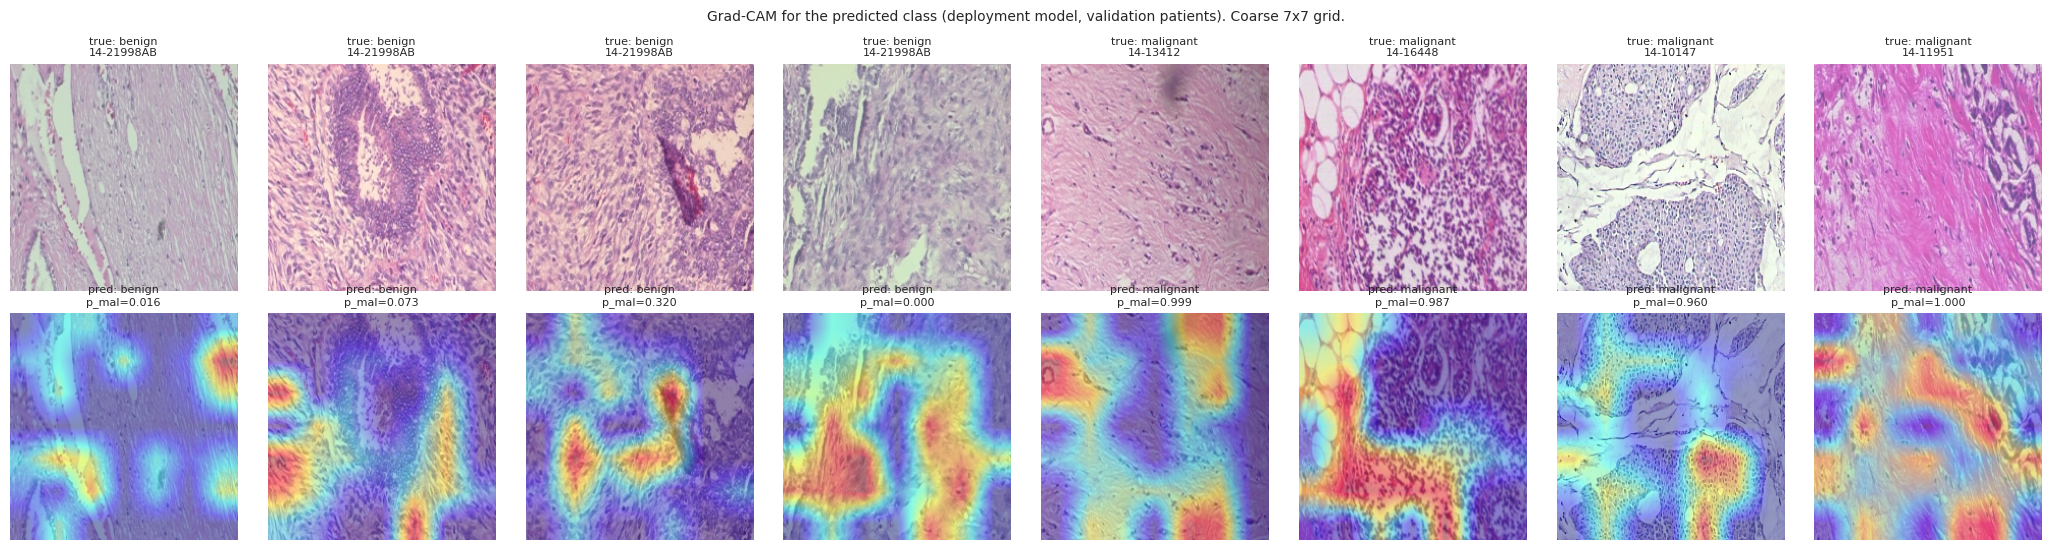

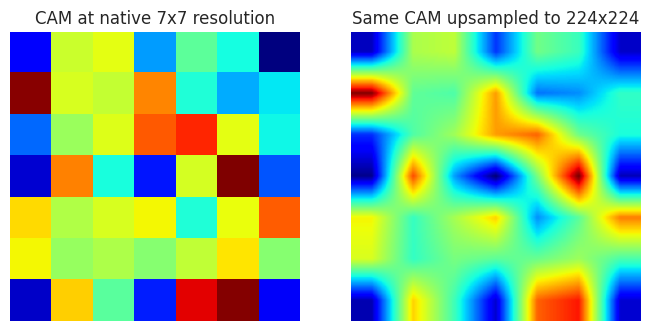

In [15]:
def explain_image(model: nn.Module, img: Image.Image, target_class: int,
                  preprocessing: Dict) -> Tuple[np.ndarray, np.ndarray]:
    """Grad-CAM for one image. Returns (cam_224 in [0,1], overlay uint8 RGB).

    Gradients are required, so this must NOT run under torch.no_grad(). A fresh GradCAM object
    is created and its hooks are removed (context manager) for every call. The app does the same.
    """
    x = build_eval_transform(preprocessing)(img).unsqueeze(0).to(next(model.parameters()).device)
    with GradCAM(model=model, target_layers=[get_cam_target_layer(model)],
                 reshape_transform=make_swin_reshape_transform(model.num_features)) as cam:
        grayscale = cam(input_tensor=x, targets=[ClassifierOutputTarget(target_class)])[0]
    rgb = np.asarray(build_resize(preprocessing)(img), dtype=np.float32) / 255.0
    overlay = show_cam_on_image(rgb, grayscale, use_rgb=True, image_weight=0.6)
    return grayscale, overlay


def predict_one(model: nn.Module, img: Image.Image, preprocessing: Dict, threshold: float) -> Dict:
    x = build_eval_transform(preprocessing)(img).unsqueeze(0).to(next(model.parameters()).device)
    with torch.no_grad():
        p = float(torch.softmax(model.eval()(x).double(), dim=1)[0, 1])
    return {'p_malignant': p, 'pred': int(p >= threshold)}


# Validation images of the deployment model (not used for weight updates), 4 per class.
rng = np.random.RandomState(SEED)
show_df = pd.concat([final_val_df[final_val_df['label'] == c].sample(4, random_state=rng) for c in CLASSES])

fig, axes = plt.subplots(2, len(show_df), figsize=(2.6 * len(show_df), 5.6))
for col, row in enumerate(show_df.itertuples()):
    img = load_rgb(row.path)
    pr = predict_one(final_model, img, PREPROCESSING, DEPLOY_THRESHOLD)
    _, overlay = explain_image(final_model, img, pr['pred'], PREPROCESSING)
    axes[0, col].imshow(build_resize(PREPROCESSING)(img))
    axes[0, col].set_title(f'true: {row.label}\n{row.patient_id}', fontsize=8)
    axes[1, col].imshow(overlay)
    axes[1, col].set_title(f"pred: {CLASSES[pr['pred']]}\np_mal={pr['p_malignant']:.3f}", fontsize=8)
    for a in axes[:, col]:
        a.axis('off')
plt.suptitle('Grad-CAM for the predicted class (deployment model, validation patients). '
             'Coarse 7x7 grid.', fontsize=10)
plt.tight_layout()
plt.show()   # displayed only. Not exported, because it contains dataset images.

# Raw 7x7 view of one image, to show how coarse the map really is.
img0 = load_rgb(show_df.iloc[-1]['path'])
cam0, _ = explain_image(final_model, img0, 1, PREPROCESSING)
cam0_grid = cv2.resize(cam0, cam_grid[::-1], interpolation=cv2.INTER_AREA)
fig, axes = plt.subplots(1, 2, figsize=(7, 3.4))
axes[0].imshow(cam0_grid, cmap='jet')
axes[0].set_title(f'CAM at native {cam_grid[0]}x{cam_grid[1]} resolution')
axes[1].imshow(cam0, cmap='jet')
axes[1].set_title('Same CAM upsampled to 224x224')
for a in axes:
    a.axis('off')
plt.tight_layout()
plt.show()

**Checklist. Continue to the export only if all of these hold:**

- [ ] The printed `block output` shape is `(1, 7, 7, 768)` and `block.norm2 output` is `(1, 49, 768)`, or the reshape handled whatever this timm version printed.
- [ ] The heatmaps differ from image to image. If every image produces the same blob, for example always the centre or a border, the target layer or the reshape is wrong.
- [ ] The highlighted regions lie mostly on tissue, not on white background or slide edges. If they don't, record it as a limitation instead of hiding it.
- [ ] The native 7×7 view makes the coarseness clear. That is what the app's explanatory text describes.

## 12. Exporting `deployment_artifacts/`

In [16]:
def sha256_file(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()


def base_version(v: Optional[str]) -> Optional[str]:
    """'2.5.1+cu121' -> '2.5.1' (for pinning the CPU wheel in Docker)."""
    return v.split('+')[0] if v else v


def jsonable(o):
    if isinstance(o, dict):
        return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [jsonable(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating, float)):
        return None if not np.isfinite(o) else float(o)
    return o


def write_json(obj, name: str) -> Path:
    path = ARTIFACT_DIR / name
    path.write_text(json.dumps(jsonable(obj), indent=2))
    return path


# ---- 1. Weights ----
weights_path = ARTIFACT_DIR / WEIGHTS_FILENAME
state = {k: v.detach().cpu().contiguous() for k, v in final_model.state_dict().items()}
save_file(state, str(weights_path), metadata={'architecture': TIMM_MODEL_NAME, 'format': 'pt'})
WEIGHTS_SHA256 = sha256_file(weights_path)

# ---- 2. model_config.json ----
model_config = {
    'schema_version': 1,
    'created_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
    'intended_use': 'Research and education demo. Not a medical device; not for clinical diagnosis.',
    'model': {
        'library': 'timm',
        'architecture': TIMM_MODEL_NAME,
        'num_classes': len(CLASSES),
        'weights_file': WEIGHTS_FILENAME,
        'weights_format': 'safetensors',
        'weights_sha256': WEIGHTS_SHA256,
        'load_recipe': "timm.create_model(architecture, pretrained=False, num_classes=2); "
                       "model.load_state_dict(safetensors.torch.load_file(weights_file), strict=True); "
                       "model.eval()",
    },
    'classes': {str(i): c for c, i in LABEL_MAP.items()},
    'positive_class': 'malignant',
    'decision': {
        'score': 'p_malignant = softmax(logits.double(), dim=1)[:, 1]',
        'rule': 'predict malignant if p_malignant >= threshold, else benign',
        'threshold': DEPLOY_THRESHOLD,
        'reference_threshold': REFERENCE_THRESHOLD,
        'selection': {
            'data': 'deployment validation holdout (patient-level, ~15% of patients)',
            'criterion': f'highest threshold with validation malignant recall >= {TARGET_MALIGNANT_RECALL}',
            **final['threshold_selection'],
            'n_val_patients': int(final_val_df['patient_id'].nunique()),
            'n_val_images': int(len(final_val_df)),
            'cv_fold_thresholds': fold_thresholds,
        },
    },
    'preprocessing': PREPROCESSING,
    'training_input': {
        'image_sizes_seen': TRAINING_IMAGE_SIZES,
        'note': 'Uploads with a different size or aspect ratio are squashed to 224x224, which may '
                'distort tissue geometry compared with the training images.',
    },
    'training': {
        'pretrained_weights': f'timm default for {TIMM_MODEL_NAME} (ImageNet)',
        'optimizer': 'AdamW', 'learning_rate': LEARNING_RATE, 'weight_decay': WEIGHT_DECAY,
        'scheduler': f'CosineAnnealingLR(T_max={NUM_EPOCHS})', 'loss': 'CrossEntropyLoss',
        'batch_size': BATCH_SIZE, 'max_epochs': NUM_EPOCHS, 'mixed_precision': 'fp16 autocast (train only)',
        'early_stopping': {'monitor': 'val_loss', 'patience': EARLY_STOPPING_PATIENCE,
                           'min_delta': EARLY_STOPPING_MIN_DELTA, 'restore': 'min val_loss weights'},
        'augmentation': TRAIN_AUGMENTATION,
        'seed': SEED,
        'best_epoch': final['training']['best_epoch'],
        'epochs_run': final['training']['epochs_run'],
        'n_train_patients': int(final_train_df['patient_id'].nunique()),
        'n_train_images': int(len(final_train_df)),
    },
    'explainability': {
        'method': 'Grad-CAM',
        'library': f"grad-cam=={VERSIONS['grad-cam']} (import pytorch_grad_cam)",
        'target_layer': CAM_TARGET_LAYER_PATH,
        'observed_shapes': {k: list(v) for k, v in shapes.items()},
        'reshape_transform': '(B,H,W,C)->permute(0,3,1,2); (B,N,C)->reshape to sqrt(N) grid; (B,C,H,W) unchanged',
        'cam_grid_hw': list(cam_grid),
        'target_class': 'predicted class (after threshold)',
        'note': f'Coarse: computed on a {cam_grid[0]}x{cam_grid[1]} grid (one cell per ~32x32 px) '
                'and upsampled to 224x224. Shows influential regions, not individual cells.',
        'overlay': 'pytorch_grad_cam.utils.image.show_cam_on_image(rgb_224_float01, cam, use_rgb=True, image_weight=0.6)',
    },
    'data': {'dataset': 'BreakHis', 'magnification': MAGNIFICATION, 'stain': 'H&E', 'url': BREAKHIS_URL},
    'versions': VERSIONS,
}
write_json(model_config, 'model_config.json')

# ---- 3. metrics.json ----
metrics = {
    'headline': {
        'description': f'Patient-level {N_FOLDS}-fold StratifiedGroupKFold (test folds), '
                       'each fold scored at its own validation-selected threshold. '
                       'This is the performance estimate shown in the app.',
        'protocol': {'outer': f'StratifiedGroupKFold(n_splits={N_FOLDS}, shuffle=True, random_state={SEED})',
                     'groups': 'patient_id parsed from filename',
                     'inner_validation': f'patient-grouped holdout ~{INNER_VAL_FRACTION:.0%} of training patients',
                     'threshold_rule': f'highest t with validation malignant recall >= {TARGET_MALIGNANT_RECALL}'},
        'at_selected_threshold': cv_selected,
        'at_0.5': cv_half,
        'fold_thresholds': fold_thresholds,
        'pooled_confusion_matrix': {'labels': CLASSES, 'matrix': oof_cm.tolist(),
                                    'rows': 'true', 'cols': 'predicted'},
        'folds': [{'fold': r['fold'] + 1, 'test_patients': r['test_patients'],
                   'best_epoch': r['training']['best_epoch'],
                   'threshold_selection': r['threshold_selection'],
                   'test_at_selected': r['test_at_selected'], 'test_at_0.5': r['test_at_0.5']}
                  for r in cv_results],
    },
    'leakage_prone_baseline': None if baseline is None else {
        'label': 'leakage-prone baseline',
        'description': 'Original image-level stratified 70/15/15 split (seed 42). Images from the same '
                       'patient can appear in train and test, so these numbers are optimistic. '
                       'Not shown as the app headline.',
        'leakage': baseline['leakage'],
        'threshold_selection': baseline['threshold_selection'],
        'test_at_selected': baseline['test_at_selected'],
        'test_at_0.5': baseline['test_at_0.5'],
    },
    'deployed_model': {
        'description': 'Trained on all patients except a patient-level validation holdout. It has no '
                       'held-out test set of its own; use the headline CV estimate for expected performance.',
        'threshold': DEPLOY_THRESHOLD,
        'validation_at_threshold': final['val_at_selected'],
        'best_epoch': final['training']['best_epoch'],
    },
    'limitations': [
        'Validation data was used for both early stopping and threshold selection, so validation '
        'metrics are optimistic and the threshold is fitted to a few patients.',
        f'Only {df["patient_id"].nunique()} patients from a single institution (BreakHis); no external validation.',
        f'Single magnification ({MAGNIFICATION}), H&E staining; other magnifications, stains or scanners are out of scope.',
        'Image-level predictions; no slide- or patient-level aggregation.',
        'Grad-CAM is computed on a coarse 7x7 grid and highlights influential regions, not diagnostic features.',
        'Research and education demo only; not for clinical use.',
    ],
}
write_json(metrics, 'metrics.json')

# ---- 4. dataset_stats.json (add split summaries) ----
DATASET_STATS['splits'] = {
    'headline_cv': f'{N_FOLDS}-fold patient-level StratifiedGroupKFold',
    'deployment_model': {
        cls: {'train_patients': int(final_train_df.loc[final_train_df['label'] == cls, 'patient_id'].nunique()),
              'train_images': int((final_train_df['label'] == cls).sum()),
              'val_patients': int(final_val_df.loc[final_val_df['label'] == cls, 'patient_id'].nunique()),
              'val_images': int((final_val_df['label'] == cls).sum())}
        for cls in CLASSES
    },
}
write_json(DATASET_STATS, 'dataset_stats.json')

# ---- 5. Split assignments (reproducibility; not used by the app) ----
pd.DataFrame(split_rows).to_csv(ARTIFACT_DIR / 'split_assignments.csv', index=False)

# ---- 6. Pinned inference requirements (copy into the app's requirements.txt) ----
req_lines = [
    '# Generated by swin_tiny_train_for_deployment.ipynb - versions match the training environment.',
    '# Install torch/torchvision from the CPU index in Docker:',
    '#   pip install --index-url https://download.pytorch.org/whl/cpu torch==X torchvision==Y',
    f"torch=={base_version(VERSIONS['torch'])}",
    f"torchvision=={base_version(VERSIONS['torchvision'])}",
    f"timm=={VERSIONS['timm']}",
    f"grad-cam=={VERSIONS['grad-cam']}",
    f"safetensors=={VERSIONS['safetensors']}",
    f"numpy=={VERSIONS['numpy']}",
    f"pillow=={VERSIONS['pillow']}",
    (f"opencv-python-headless=={VERSIONS['opencv_distribution'].split('==')[1]}"
     if VERSIONS['opencv_distribution'] else '# opencv-python-headless: version not detected'),
]
(ARTIFACT_DIR / 'requirements-pinned.txt').write_text('\n'.join(req_lines) + '\n')

print('Exported:')
for p in sorted(ARTIFACT_DIR.iterdir()):
    print(f'  {p.name:<36} {p.stat().st_size / 1e6:8.2f} MB')

Exported:
  class_distribution.png                   0.05 MB
  cv_confusion_matrix.png                  0.04 MB
  cv_roc_curve.png                         0.07 MB
  dataset_stats.json                       0.00 MB
  metrics.json                             0.02 MB
  model_config.json                        0.01 MB
  requirements-pinned.txt                  0.00 MB
  split_assignments.csv                    1.00 MB
  swin_tiny_breakhis.safetensors         110.10 MB
  training_history.png                     0.09 MB


## 13. Reload test: does the exported model behave like the trained one?

This loads only what the app will have: `model_config.json` and the safetensors file. It rebuilds the model and the preprocessing from the config, then checks:

1. The weights file's SHA-256 matches the config, and `load_state_dict(strict=True)` succeeds.
2. GPU probabilities on the deployment validation images match the in-memory model (`atol=1e-5`).
3. On **CPU**, which is how the app runs, the probabilities and the thresholded predictions match.
4. Grad-CAM from the reloaded CPU model matches the in-memory model's map.

In [17]:
cfg = json.loads((ARTIFACT_DIR / 'model_config.json').read_text())
w_path = ARTIFACT_DIR / cfg['model']['weights_file']
assert sha256_file(w_path) == cfg['model']['weights_sha256'], 'Weights checksum mismatch'

reloaded = timm.create_model(cfg['model']['architecture'], pretrained=False,
                             num_classes=cfg['model']['num_classes'])
reloaded.load_state_dict(load_file(str(w_path)), strict=True)
reloaded.eval()

cfg_transform = build_eval_transform(cfg['preprocessing'])
thr = cfg['decision']['threshold']


@torch.no_grad()
def probs_via_config(model: nn.Module, paths: List[str], device: torch.device) -> np.ndarray:
    model = model.to(device).eval()
    out = []
    for i in range(0, len(paths), BATCH_SIZE):
        x = torch.stack([cfg_transform(load_rgb(p)) for p in paths[i:i + BATCH_SIZE]]).to(device)
        out.append(torch.softmax(model(x).double(), dim=1)[:, 1].cpu().numpy())
    return np.concatenate(out)


paths = final_val_df['path'].tolist()
p_orig = probs_via_config(final_model, paths, DEVICE)
p_reload_gpu = probs_via_config(reloaded, paths, DEVICE)
p_reload_cpu = probs_via_config(reloaded, paths, torch.device('cpu'))

d_gpu = np.abs(p_orig - p_reload_gpu).max()
d_cpu = np.abs(p_orig - p_reload_cpu).max()
flips_cpu = int(((p_orig >= thr) != (p_reload_cpu >= thr)).sum())
print(f'max |p_orig - p_reload_gpu| = {d_gpu:.2e}')
print(f'max |p_orig - p_reload_cpu| = {d_cpu:.2e}; prediction flips at threshold on CPU: {flips_cpu}')
assert d_gpu < 1e-5, 'Reloaded GPU model differs from the trained model'
assert d_cpu < 1e-3, 'CPU inference differs more than expected from GPU'
if flips_cpu:
    print('WARNING: some images sit within GPU/CPU numerical noise of the threshold.')

# Also confirm the DataLoader path used during training matches the config path.
_, p_loader = predict_proba(final_model, make_loader(final_val_df, False, SEED))
assert np.abs(p_loader - p_orig).max() < 1e-5, 'Training-time and config-built preprocessing differ'

img_chk = load_rgb(paths[0])
cam_a, _ = explain_image(final_model, img_chk, 1, PREPROCESSING)
cam_b, _ = explain_image(reloaded.cpu(), img_chk, 1, cfg['preprocessing'])
print(f'max |CAM_orig - CAM_reload_cpu| = {np.abs(cam_a - cam_b).max():.2e}')
assert np.abs(cam_a - cam_b).max() < 1e-2, 'Grad-CAM differs between trained and reloaded model'
print('\nReload test passed.')

max |p_orig - p_reload_gpu| = 0.00e+00
max |p_orig - p_reload_cpu| = 6.69e-07; prediction flips at threshold on CPU: 1
max |CAM_orig - CAM_reload_cpu| = 0.00e+00

Reload test passed.


## 14. Summary

The cell below prints the headline numbers that the app will display, together with the leakage-prone baseline for comparison. When it finishes, download the `deployment_artifacts/` folder from Drive for the FastAPI app.

In [18]:
def fmt(d: Dict) -> str:
    return f"{d['mean']:.4f} ± {d['std']:.4f}"


print(f'HEADLINE - patient-level {N_FOLDS}-fold CV, at validation-selected thresholds')
for m in ['malignant_recall', 'benign_recall', 'balanced_accuracy', 'roc_auc', 'weighted_f1']:
    print(f'  {m:<20} {fmt(cv_selected[m])}   (at 0.5: {fmt(cv_half[m])})')
if baseline is not None:
    print('\nLEAKAGE-PRONE BASELINE - image-level split (not used in the app)')
    for m in ['malignant_recall', 'benign_recall', 'balanced_accuracy', 'roc_auc', 'weighted_f1']:
        print(f"  {m:<20} {baseline['test_at_selected'][m]:.4f}")
    print(f"  leaked test patients: {baseline['leakage']['test_patients_also_in_train']}"
          f"/{baseline['leakage']['test_patients']}")
print(f'\nDeployed threshold: {DEPLOY_THRESHOLD:.4f}  |  artifacts: {ARTIFACT_DIR}')

HEADLINE - patient-level 5-fold CV, at validation-selected thresholds
  malignant_recall     0.9380 ± 0.0669   (at 0.5: 0.9453 ± 0.0418)
  benign_recall        0.7770 ± 0.2051   (at 0.5: 0.8265 ± 0.0935)
  balanced_accuracy    0.8575 ± 0.0863   (at 0.5: 0.8859 ± 0.0430)
  roc_auc              0.9615 ± 0.0321   (at 0.5: 0.9615 ± 0.0321)
  weighted_f1          0.8946 ± 0.0605   (at 0.5: 0.9109 ± 0.0400)

LEAKAGE-PRONE BASELINE - image-level split (not used in the app)
  malignant_recall     0.8935
  benign_recall        1.0000
  balanced_accuracy    0.9468
  roc_auc              0.9995
  weighted_f1          0.9283
  leaked test patients: 78/78

Deployed threshold: 0.3399  |  artifacts: /content/drive/MyDrive/DATASET MASTERS THESIS/Breast Cancer/deployment_artifacts
